# NumCompute-DecisionTree Quickstart

A short example of how to use NumCompute-Decision tree to train a model.

**To run it:**
1. From the project root, run `uv sync` (see the README).
2. Open this notebook and choose the `.venv` Python as the kernel. If VS Code asks to install `ipykernel`, accept.
3. Run all cells from top to bottom. Paths assume the notebook runs from the `demo/` folder.

In [42]:
from pathlib import Path
import numpy as np

DATA_DIR = Path("..") / "tests" / "test_csv_files"

## 1. Loading data (`io`)

`load_csv` reads a CSV into a 2D float array. Missing values become `NaN`.

In [44]:
from numcompute_stream import load_csv, DecisionTreeClassifier

X = load_csv(DATA_DIR / "loan_data_streaming.csv", skip_header = 1)
features, labels = X[:, :-1], X[:, -1].astype(int)

chunk_size = 20   # gives 10 chunks
chunks = [
    (features[i:i + chunk_size], labels[i:i + chunk_size])
    for i in range(0, len(features), chunk_size)
]

print(X.shape)

(200, 5)


# Chunking the data

To simulate a streaming environment the loaded data is split into chunks. Then it is fed into the pipeline, then a model. The model is then evaluated via the Metrics and Visualisation

In [45]:
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import StandardScaler, MinMaxScaler

## 2. Pipeline (`pipeline`)

`Pipeline` chains multiple preprocessing steps such that the output of a transformer is automatically passed as the input of the next.

### Chaining preprocessing steps

`fit_transform` fits each transformer in a sequence, returning only the final transformed data.

In [46]:
pipe = Pipeline([
        ("scale", StandardScaler()),
        ("minmax", MinMaxScaler()),
    ])
model = DecisionTreeClassifier()

for X_chunk, y_chunk in chunks:
    X_t = pipe.partial_fit_transform(X_chunk)   # update the pipeline on this chunk and transform it
    model.partial_fit(X_t, y_chunk)


DEBUG self.var: array([0.24  , 0.21  , 0.1875, 0.25  ]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.244375, 0.2275  , 0.244375, 0.25    ]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.2475    , 0.24555556, 0.24888889, 0.24972222]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.24984375, 0.24859375, 0.249375  , 0.24984375]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.2496, 0.2484, 0.2496, 0.2496]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.249375  , 0.24659722, 0.24972222, 0.24993056]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.24872449, 0.24382653, 0.24994898, 0.24979592]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.24902344, 0.244375  , 0.24996094, 0.24984375]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.24950617, 0.2475    , 0.25      , 0.24987654]) <class 'numpy.ndarray'>
DEBUG self.var: array([0.249975, 0.248775, 0.249375, 0.249775]) <class 'numpy.ndarray'>


## 4. Metrics and Visualisation
These are implementations of basic machine learning metrics. Predicted results and actual results are required, this will take results on the pipeline above and then stream the appropriate metrics.

In [54]:
from numcompute_stream.metrics import StreamMetrics
stream_metrics = StreamMetrics()
stream = DecisionTreeClassifier()

for i, (x_chunk, y_chunk) in enumerate(chunks):
    if i > 0:
        y_pred = model.predict(x_chunk)
        stream_metrics.update(y_chunk, y_pred)
        print(f"\n chunk {i}:", stream_metrics.result())




 chunk 1: {'Accuracy': np.float64(0.75), 'Precision': np.float64(1.0), 'Recall': np.float64(0.5833333333333334), 'F1 Score': np.float64(0.7368421052631579), 'Confusion Matrix': (np.int64(7), np.int64(0), np.int64(8), np.int64(5)), 'MSE': np.float64(0.25)}

 chunk 2: {'Accuracy': np.float64(0.8), 'Precision': np.float64(1.0), 'Recall': np.float64(0.6521739130434783), 'F1 Score': np.float64(0.7894736842105263), 'Confusion Matrix': (np.int64(15), np.int64(0), np.int64(17), np.int64(8)), 'MSE': np.float64(0.2)}

 chunk 3: {'Accuracy': np.float64(0.8), 'Precision': np.float64(1.0), 'Recall': np.float64(0.625), 'F1 Score': np.float64(0.7692307692307693), 'Confusion Matrix': (np.int64(20), np.int64(0), np.int64(28), np.int64(12)), 'MSE': np.float64(0.2)}

 chunk 4: {'Accuracy': np.float64(0.8125), 'Precision': np.float64(1.0), 'Recall': np.float64(0.6590909090909091), 'F1 Score': np.float64(0.7945205479452054), 'Confusion Matrix': (np.int64(29), np.int64(0), np.int64(36), np.int64(15)), 'MSE

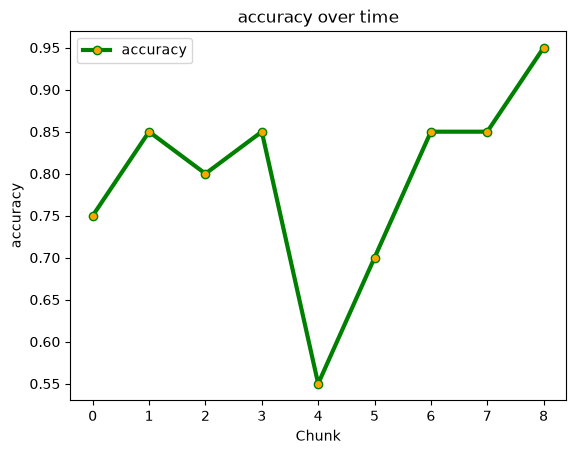

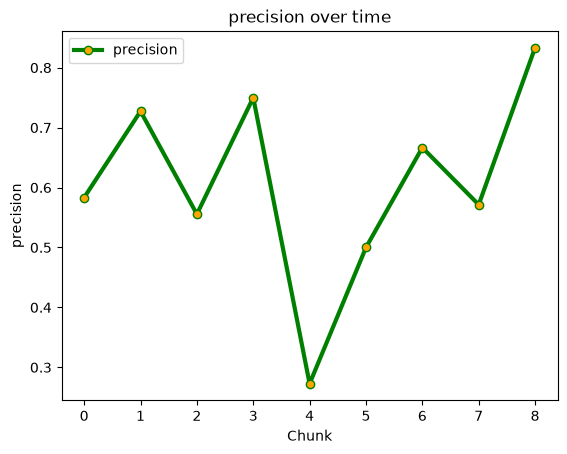

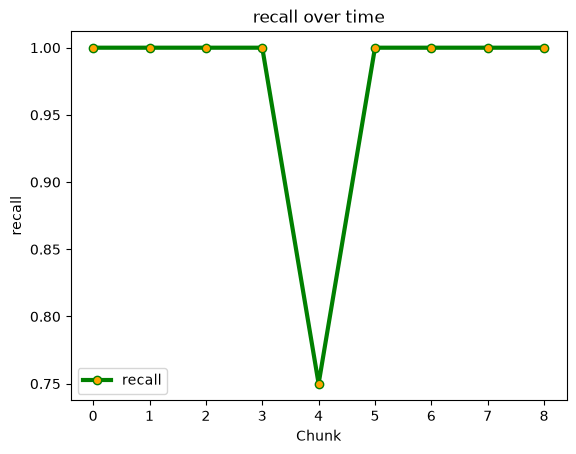

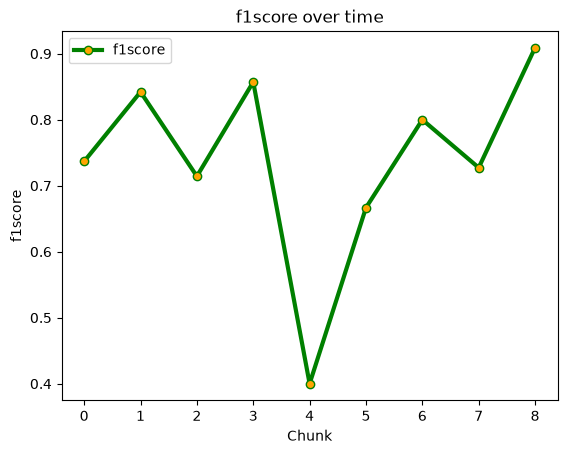

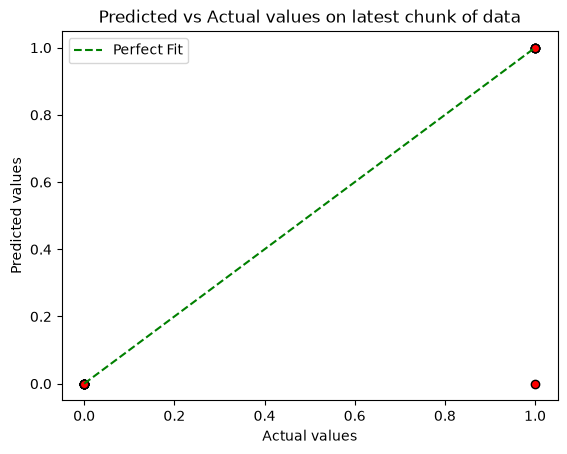

In [56]:
from numcompute_stream.visualise import VisualiseMetrics
from numcompute_stream.metrics import StreamMetrics

stream_metrics = StreamMetrics()
stream_visualise = VisualiseMetrics()
stream = DecisionTreeClassifier()

# Visualizing accuracy over time
for i, (x_chunk, y_chunk) in enumerate(chunks):
    if i > 0:
        y_pred = model.predict(x_chunk)
        #Plotting metrics over time
        stream_visualise.plot_metric_over_time(stream_metrics.accuracy(y_chunk, y_pred), "accuracy")
        stream_visualise.plot_metric_over_time(stream_metrics.precision(y_chunk, y_pred), "precision")
        stream_visualise.plot_metric_over_time(stream_metrics.recall(y_chunk, y_pred), "recall")
        stream_visualise.plot_metric_over_time(stream_metrics.f1score(y_chunk, y_pred), "f1score")

        #Predictions vs Ground Truth
        stream_visualise.plot_predictions_vs_ground_truth(y_chunk,y_pred)

